# Sequence Modeling with Recurrent Neural Networks (RNN, LSTM, GRU) - 2026

**Course:** Machine Learning for Geologists & Geocomputation (Spatial Ecology 2026)  
**Instructor:** Raffaele Scaringi  
**Dataset:** [NOAA Global Historical Climatology - Seattle Daily Meteorological Observations](https://raw.githubusercontent.com/vega/vega-datasets/master/data/seattle-weather.csv)  
**Format:** Single Self-Contained Lecture & Practical Notebook  

---

### Course Progression Recap
* **Class 1-3:** Perceptrons, Multi-Layer Perceptrons (MLPs), and Optimizers (Gradient Descent, Momentum, Adam).
* **Class 4:** Deep Feedforward Networks on Tabular Earth Data.
* **Class 5:** Convolutional Neural Networks (CNNs) for Spatial Satellite Imagery (Sentinel-2 EuroSAT).
* **Class 6 (Today):** **Sequence Modeling & Recurrent Architectures** for dynamic temporal and depth-dependent geological processes.

---

### Pedagogical Learning Objectives
1. **The Sequence Modeling Paradigm:** Understand why 2D feedforward networks fail on temporal and spatial sequences, and how recurrent connections maintain an internal hidden memory state.
2. **Real-World Environmental Data Ingestion:** Load real-world daily meteorological observations directly from a public URL into Pandas without external credentials.
3. **Exploratory Data Analysis (EDA):** Inspect atmospheric dynamics, seasonal thermal cycles, and the heavy-tailed intermittent nature of precipitation.
4. **Strict Temporal Validation (Zero Data Leakage):** Why standard randomized cross-validation (`shuffle=True`) is fatal for geoscientific time series, and how to execute proper chronological block splitting.
5. **Geoscientific Feature Preprocessing:** Apply physical transforms (e.g., logarithmic scaling for zero-inflated precipitation) and feature normalization fitted strictly on historical observations.
6. **PyTorch 3D Sequence Windowing:** Master the PyTorch 3D recurrent tensor contract: `(Batch_Size, Sequence_Length, Num_Features)`.
7. **Vanilla RNN & The Vanishing Gradient Pathology:** Build a Vanilla RNN from scratch with `torch.nn.RNN` and mathematically/empirically observe gradient decay during Backpropagation Through Time (BPTT).
8. **Defensive Engineering with Gradient Clipping:** Prevent exploding gradients using `torch.nn.utils.clip_grad_norm_`.
9. **Long Short-Term Memory (LSTM):** Deconstruct the LSTM cell architecture: Forget, Input, and Output gates protecting the linear **Cell State Highway** (Constant Error Carousel).
10. **Gated Recurrent Unit (GRU):** Compare GRU's merged hidden/cell state and evaluate its parameter efficiency vs. LSTM.
11. **Geoscientific Model Evaluation:** Benchmark models against the **Persistence Baseline** using hydrometeorological metrics: RMSE, MAE, $R^2$, and the **Nash-Sutcliffe Efficiency ($NSE$)**.
12. **Physical Interpretability:** Probe the internal cell state channels of the trained LSTM to reveal how deep recurrent layers store seasonal energy vs. short-term synoptic fronts.
13. **Bidirectional Recurrent Networks (BiLSTM) for Spatial Sequences:** Understand why spatial geological profiles (borehole well-logging, stratigraphic sequences) require non-causal bidirectional context.


In [1]:
# 1. Imports, Determinism & Device Configuration
import os
import random
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# Configure Matplotlib styling for high-contrast geoscientific figures
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# Ensure complete reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"[INFO] PyTorch Version: {torch.__version__}")
print(f"[INFO] Computing Device: {device}")


[INFO] PyTorch Version: 2.12.0+cu130
[INFO] Computing Device: cuda


## 1. Real-World Environmental Data Acquisition

In geoscience and environmental computing, synthetic toy data often masks the true complexities of natural processes:
* **Intermittency:** Rainfall consists of prolonged zeros punctuated by intense non-linear bursts.
* **Thermal Inertia & Atmospheric Memory:** Surface temperatures do not vary randomly; soil thermal mass and synoptic pressure systems store memory across days and weeks.
* **Seasonal Periodicity:** Strong annual solar forcing superimposed with daily weather noise.

### The Dataset: NOAA Seattle Daily Weather Record (2012-2015)
We acquire a real-world multi-variate meteorological record directly from a public permanent CDN:
* **Source:** National Oceanic and Atmospheric Administration (NOAA) Global Historical Climatology Network.
* **Span:** 4 continuous calendar years (2012-01-01 to 2015-12-31 = 1,461 daily records).
* **Observed Variables:**
  * `date`: Daily observation timestamp.
  * `precipitation`: Total daily rainfall (mm).
  * `temp_max`: Maximum daily air temperature (deg C).
  * `temp_min`: Minimum daily air temperature (deg C).
  * `wind`: Mean daily wind speed (m/s).
  * `weather`: Qualitative weather summary (drizzle, rain, sun, snow, fog).


In [2]:
# 2. Ingest Dataset Directly from Public Source URL
DATA_URL = "https://raw.githubusercontent.com/vega/vega-datasets/master/data/seattle-weather.csv"

print(f"[INFO] Fetching real-world meteorological data from: {DATA_URL}")
df_raw = pd.read_csv(DATA_URL)
df_raw['date'] = pd.to_datetime(df_raw['date'])
df_raw = df_raw.sort_values('date').reset_index(drop=True)

print(f"[INFO] Successfully loaded {len(df_raw)} daily observations.")
print(f"[INFO] Date range: {df_raw['date'].min().strftime('%Y-%m-%d')} to {df_raw['date'].max().strftime('%Y-%m-%d')}")
print("[INFO] Missing values across all columns:")
print(df_raw.isnull().sum())

# Inspect first 5 records
display(df_raw.head())


[INFO] Fetching real-world meteorological data from: https://raw.githubusercontent.com/vega/vega-datasets/master/data/seattle-weather.csv
[INFO] Successfully loaded 1461 daily observations.
[INFO] Date range: 2012-01-01 to 2015-12-31
[INFO] Missing values across all columns:
date             0
precipitation    0
temp_max         0
temp_min         0
wind             0
weather          0
dtype: int64


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


## 2. Exploratory Data Analysis & Geological/Atmospheric Dynamics

Before training any neural network, an Earth scientist must visualize the raw data to understand physical dynamics:
1. **Seasonal Thermal Envelope:** The smooth sinusoidal oscillation of solar radiation creates the temperature envelope ($T_{\max}$ and $T_{\min}$).
2. **Episodic Precipitation:** Precipitation is highly skewed and sparse (zero-inflated). Traditional neural networks with mean squared error struggle with extreme positive values unless properly scaled.
3. **Atmospheric Inertia & Cross-Correlation:** Cold/warm fronts persist over multi-day windows. Today's temperature is strongly correlated with yesterday's, but non-linear shifts occur when precipitation fronts pass through.


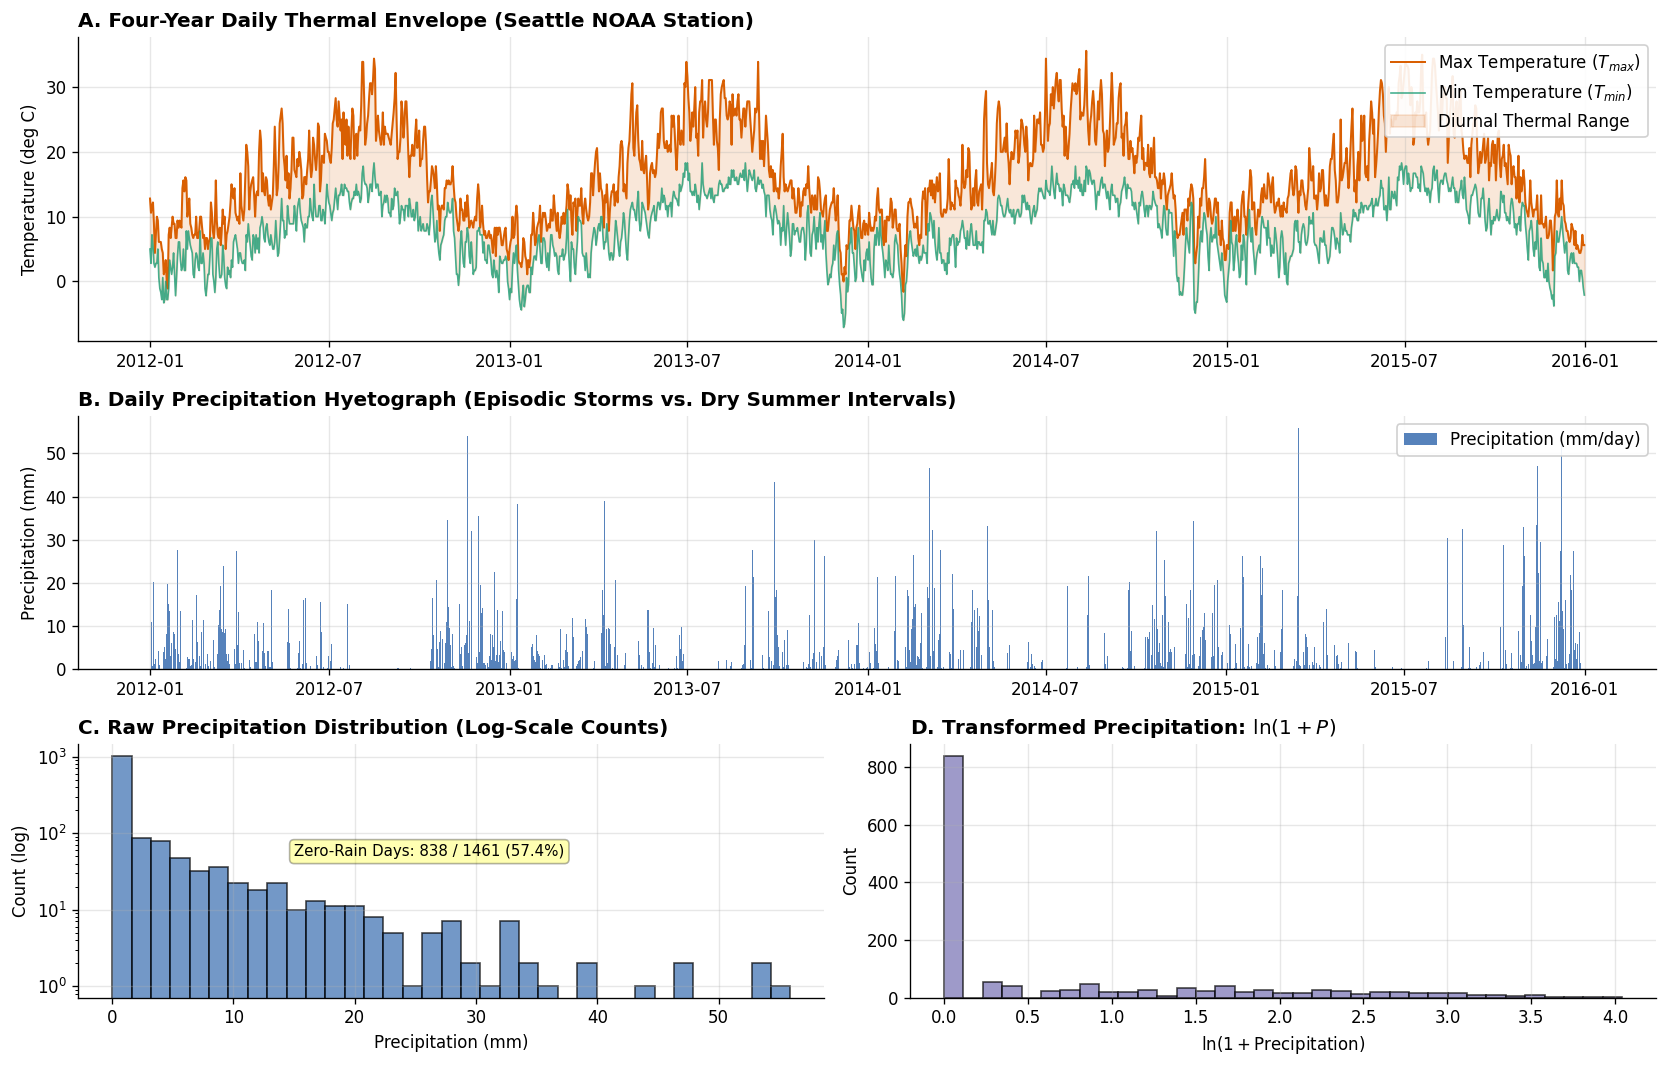

In [3]:
# 3. Exploratory Data Analysis: Time Series Dynamics and Distribution Skewness
fig = plt.figure(figsize=(14, 9))
gs = fig.add_gridspec(3, 2, height_ratios=[1.2, 1.0, 1.0])

# Subplot 1: Temperature Envelope over 4 Years
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(df_raw['date'], df_raw['temp_max'], color='#d95f02', lw=1.2, label='Max Temperature ($T_{max}$)')
ax1.plot(df_raw['date'], df_raw['temp_min'], color='#1b9e77', lw=1.0, alpha=0.8, label='Min Temperature ($T_{min}$)')
ax1.fill_between(df_raw['date'], df_raw['temp_min'], df_raw['temp_max'], color='#d95f02', alpha=0.15, label='Diurnal Thermal Range')
ax1.set_title("A. Four-Year Daily Thermal Envelope (Seattle NOAA Station)", fontweight='bold', loc='left')
ax1.set_ylabel("Temperature (deg C)")
ax1.legend(loc='upper right', framealpha=0.9)

# Subplot 2: Daily Precipitation Hyetograph
ax2 = fig.add_subplot(gs[1, :])
ax2.bar(df_raw['date'], df_raw['precipitation'], color='#386cb0', width=1.0, alpha=0.85, label='Precipitation (mm/day)')
ax2.set_title("B. Daily Precipitation Hyetograph (Episodic Storms vs. Dry Summer Intervals)", fontweight='bold', loc='left')
ax2.set_ylabel("Precipitation (mm)")
ax2.legend(loc='upper right', framealpha=0.9)

# Subplot 3: Raw Precipitation Distribution (Heavy-Tailed Skewness)
ax3 = fig.add_subplot(gs[2, 0])
ax3.hist(df_raw['precipitation'], bins=35, color='#386cb0', edgecolor='black', alpha=0.7)
ax3.set_yscale('log')
ax3.set_title("C. Raw Precipitation Distribution (Log-Scale Counts)", fontweight='bold', loc='left')
ax3.set_xlabel("Precipitation (mm)")
ax3.set_ylabel("Count (log)")
zero_pct = ((df_raw['precipitation'] == 0).sum() / len(df_raw)) * 100
ax3.annotate(f"Zero-Rain Days: {(df_raw['precipitation'] == 0).sum()} / {len(df_raw)} ({zero_pct:.1f}%)",
             xy=(15, 50), fontsize=9, bbox=dict(boxstyle="round,pad=0.3", fc="yellow", alpha=0.3))

# Subplot 4: Log-Transformed Precipitation: log(1 + P)
ax4 = fig.add_subplot(gs[2, 1])
log_precip = np.log1p(df_raw['precipitation'])
ax4.hist(log_precip, bins=35, color='#7570b3', edgecolor='black', alpha=0.7)
ax4.set_title("D. Transformed Precipitation: $\\ln(1 + P)$", fontweight='bold', loc='left')
ax4.set_xlabel("$\\ln(1 + \\text{Precipitation})$")
ax4.set_ylabel("Count")

plt.tight_layout()
plt.show()


## 3. The Golden Rule of Earth Time Series: Zero Data Leakage

In standard tabular machine learning (e.g., classifying rock specimens or predicting soil properties), random shuffling (`train_test_split(shuffle=True)`) is standard practice.

> ### [WARNING] Critical Pitfall: Random Shuffling on Time Series
> In environmental and Earth observation time series, **random shuffling is completely invalid**.  
> If day $t$ is in the training set and day $t+1$ is in the test set, the model simply interpolates between neighboring days due to **strong temporal autocorrelation**. This results in unrealistically low validation loss that catastrophically collapses in real-world deployment.

### Chronological Block Split
We enforce a strict temporal boundary:
* **Training Set:** 2012-01-01 to 2014-12-31 (3 full calendar years = 1,096 days, ~75% of data).
* **Test Set:** 2015-01-01 to 2015-12-31 (1 full calendar year = 365 days, ~25% of data).
* The model must forecast the unseen future of 2015 using exclusively patterns learned from the past (2012-2014).


[INFO] Training Period: 2012-01-01 to 2014-12-31 (1096 days)
[INFO] Test Period:     2015-01-01 to 2015-12-31 (365 days)


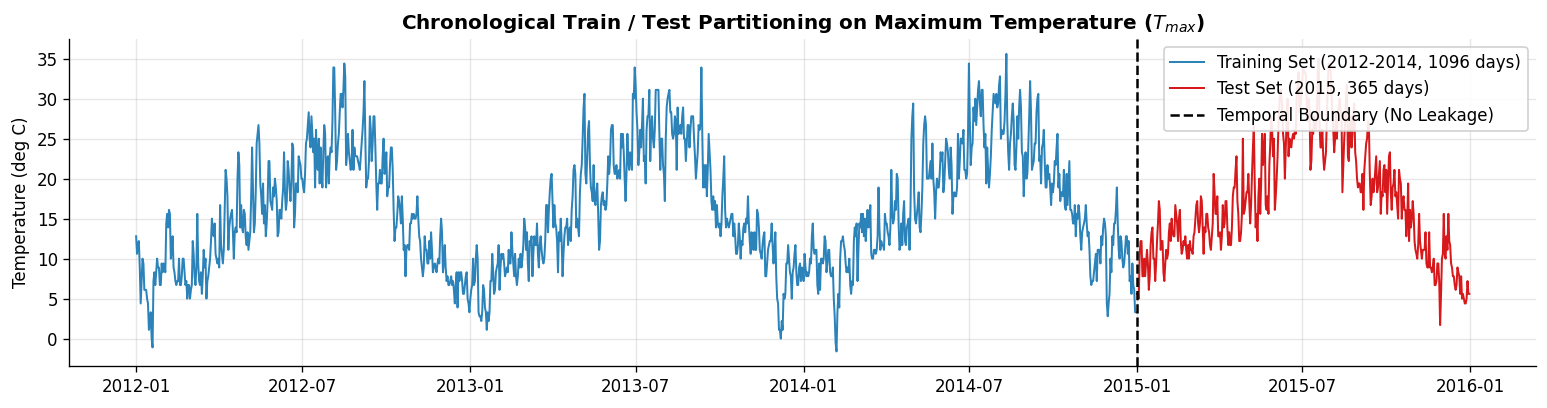

In [4]:
# 4. Strict Chronological Block Splitting
SPLIT_DATE = pd.to_datetime('2015-01-01')

train_mask = df_raw['date'] < SPLIT_DATE
test_mask = df_raw['date'] >= SPLIT_DATE

df_train = df_raw[train_mask].copy().reset_index(drop=True)
df_test = df_raw[test_mask].copy().reset_index(drop=True)

print(f"[INFO] Training Period: {df_train['date'].min().strftime('%Y-%m-%d')} to {df_train['date'].max().strftime('%Y-%m-%d')} ({len(df_train)} days)")
print(f"[INFO] Test Period:     {df_test['date'].min().strftime('%Y-%m-%d')} to {df_test['date'].max().strftime('%Y-%m-%d')} ({len(df_test)} days)")

# Visualize the temporal split
plt.figure(figsize=(13, 3.5))
plt.plot(df_train['date'], df_train['temp_max'], color='#2b83ba', label='Training Set (2012-2014, 1096 days)', lw=1.2)
plt.plot(df_test['date'], df_test['temp_max'], color='#d7191c', label='Test Set (2015, 365 days)', lw=1.2)
plt.axvline(SPLIT_DATE, color='black', linestyle='--', lw=1.5, label='Temporal Boundary (No Leakage)')
plt.title("Chronological Train / Test Partitioning on Maximum Temperature ($T_{max}$)", fontweight='bold')
plt.ylabel("Temperature (deg C)")
plt.legend(loc='upper right', framealpha=0.9)
plt.tight_layout()
plt.show()


## 4. Geoscientific Feature Preprocessing & Domain Scaling

Recurrent neural networks compute affine transformations followed by non-linear activations ($\tanh$ and $\sigma$). Unscaled variables with wildly different physical units (e.g., wind in m/s vs temperature in deg C vs precipitation in mm) cause gradient oscillations.

### Transformations Applied:
1. **Precipitation:** As demonstrated in EDA, precipitation is zero-inflated and positively skewed. We compress its dynamic range using the natural logarithmic transform:
   $$P_{\log} = \ln(1 + P)$$
2. **Z-Score Normalization:**
   $$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$
   **Crucial Rule:** The scaler parameters (mean $\mu$ and standard deviation $\sigma$) are calculated **strictly on the training partition** and then applied to the test partition. Calculating $\mu$ on the entire dataset would constitute subtle future data leakage!


In [5]:
# 5. Geoscientific Feature Engineering & Leak-Free Normalization
FEATURE_COLS = ['precip_log', 'temp_max', 'temp_min', 'wind']
TARGET_COL = 'temp_max'

# Apply log1p transform to precipitation on the full dataframe
df_raw['precip_log'] = np.log1p(df_raw['precipitation'])

# Extract raw numpy feature matrices for train and test
train_raw_feats = df_raw.loc[train_mask, FEATURE_COLS].values
test_raw_feats = df_raw.loc[test_mask, FEATURE_COLS].values

# Fit StandardScaler STRICTLY on the training set
scaler = StandardScaler()
train_scaled_feats = scaler.fit_transform(train_raw_feats)
test_scaled_feats = scaler.transform(test_raw_feats)

# Store target mean and std for exact inverse transformation during evaluation
target_idx = FEATURE_COLS.index(TARGET_COL)
TARGET_MEAN = scaler.mean_[target_idx]
TARGET_STD = scaler.scale_[target_idx]

print("[INFO] Feature Scaler Parameters (Fitted on Training Set Only):")
for col_name, m, s in zip(FEATURE_COLS, scaler.mean_, scaler.scale_):
    print(f"  - {col_name:12s}: Mean = {m:7.3f}, Std = {s:7.3f}")

print()
print(f"[INFO] Target Variable '{TARGET_COL}' has unscaling equation: y_celsius = (y_scaled * {TARGET_STD:.3f}) + {TARGET_MEAN:.3f}")


[INFO] Feature Scaler Parameters (Fitted on Training Set Only):
  - precip_log  : Mean =   0.712, Std =   1.014
  - temp_max    : Mean =  16.110, Std =   7.330
  - temp_min    : Mean =   8.035, Std =   5.073
  - wind        : Mean =   3.268, Std =   1.471

[INFO] Target Variable 'temp_max' has unscaling equation: y_celsius = (y_scaled * 7.330) + 16.110


## 5. 3D Sequence Tensor Windowing in PyTorch

In feedforward networks, tabular data has shape `(Batch_Size, Num_Features)`.  
In convolutional networks, spatial images have shape `(Batch_Size, Channels, Height, Width)`.  
In recurrent networks (RNN, LSTM, GRU), time series tensors require a 3D contract:

$$\mathbf{X} \in \mathbb{R}^{\text{Batch Size} \times \text{Sequence Length} \times \text{Number of Features}}$$

```
                      Sequence Length (L = 30 days)
               [ t-29,  t-28,  t-27,  ...,   t   ]
Feature 0 (P)   [ 0.1,   0.0,   1.2,  ...,  0.0  ]  --> Predict Target:
Feature 1 (Tmax)[ 12.3, 13.1,  11.8,  ...,  14.2 ]      Tmax at day t+1
Feature 2 (Tmin)[  5.1,  6.0,   4.5,  ...,   7.1 ]
Feature 3 (Wind)[  3.2,  2.8,   4.1,  ...,   3.0 ]
```

### Warm-up History for the Test Year
If we test on 2015, we need 30 days of prior history to predict day 1 (2015-01-01). We concatenate the final $L=30$ days of 2014 as the warm-up sequence for the test set. This ensures we evaluate **all 365 days of 2015** without throwing away the first month!


In [6]:
# 6. PyTorch Dataset with Sliding Windows
SEQ_LEN = 30   # 30-day lookback window
BATCH_SIZE = 32

class WeatherSequenceDataset(Dataset):
    # Custom PyTorch Dataset for sliding-window sequence modeling
    def __init__(self, feature_array, target_idx, seq_len=30):
        self.X, self.y = [], []
        n_samples = len(feature_array) - seq_len
        for i in range(n_samples):
            # Sequence from day i to day i + seq_len
            self.X.append(feature_array[i : i + seq_len])
            # Target is the temp_max at day i + seq_len (next day)
            self.y.append(feature_array[i + seq_len, target_idx])
            
        self.X = torch.tensor(np.array(self.X), dtype=torch.float32)
        self.y = torch.tensor(np.array(self.y), dtype=torch.float32).unsqueeze(1)
        
    def __len__(self):
        return len(self.X)
    
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create Training Dataset
train_dataset = WeatherSequenceDataset(train_scaled_feats, target_idx=target_idx, seq_len=SEQ_LEN)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)

# Prepare Test Set with 30-day warm-up from late 2014
test_warmup_feats = np.vstack([train_scaled_feats[-SEQ_LEN:], test_scaled_feats])
test_dataset = WeatherSequenceDataset(test_warmup_feats, target_idx=target_idx, seq_len=SEQ_LEN)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"[INFO] Train Dataset: {len(train_dataset)} sliding windows of shape (L={SEQ_LEN}, D={len(FEATURE_COLS)})")
print(f"[INFO] Test Dataset:  {len(test_dataset)} sliding windows (Exactly 365 daily forecasts for year 2015)")

# Verify sample batch dimensions
sample_X, sample_y = next(iter(train_loader))
print(f"[INFO] Batch Input Tensor Shape:  {sample_X.shape} -> (Batch, Seq_Len, Features)")
print(f"[INFO] Batch Target Tensor Shape: {sample_y.shape} -> (Batch, 1)")


[INFO] Train Dataset: 1066 sliding windows of shape (L=30, D=4)
[INFO] Test Dataset:  365 sliding windows (Exactly 365 daily forecasts for year 2015)
[INFO] Batch Input Tensor Shape:  torch.Size([32, 30, 4]) -> (Batch, Seq_Len, Features)
[INFO] Batch Target Tensor Shape: torch.Size([32, 1]) -> (Batch, 1)


## 6. Part 1: Vanilla RNN & The Vanishing Gradient Pathology

A standard Vanilla Recurrent Neural Network processes input vectors $\mathbf{x}_t$ sequentially using a recurrent recurrence relation:

$$\mathbf{h}_t = \tanh\left(\mathbf{W}_{ih} \mathbf{x}_t + \mathbf{W}_{hh} \mathbf{h}_{t-1} + \mathbf{b}_h\right)$$
$$\hat{y}_t = \mathbf{W}_{hy} \mathbf{h}_t + b_y$$

### The Mathematical Pathology: Backpropagation Through Time (BPTT)
To compute the gradient of the loss $\mathcal{L}_T$ at time step $T$ with respect to the initial hidden state $\mathbf{h}_1$, we apply the multivariable chain rule across all intermediate time steps:

$$\frac{\partial \mathcal{L}_T}{\partial \mathbf{h}_1} = \frac{\partial \mathcal{L}_T}{\partial \mathbf{h}_T} \prod_{k=2}^T \frac{\partial \mathbf{h}_k}{\partial \mathbf{h}_{k-1}} = \frac{\partial \mathcal{L}_T}{\partial \mathbf{h}_T} \prod_{k=2}^T \text{diag}\left(1 - \mathbf{h}_k^2\right) \mathbf{W}_{hh}^T$$

Notice the product of Jacobians:
1. **Vanishing Gradients:** The derivative of $\tanh(z)$ is $1 - \tanh^2(z) \in (0, 1]$. Multiplying numbers smaller than 1 across $T=30$ steps results in exponential decay: $0.5^{30} \approx 9.3 \times 10^{-10}$. The network **forgets early sequence signals** and cannot learn long-term seasonal trends!
2. **Exploding Gradients:** If the eigenvalues of $\mathbf{W}_{hh}$ exceed 1, the product explodes toward infinity: $\|\mathbf{W}_{hh}\|^T \to \infty$, causing numerical overflow (`NaN` loss) and weight divergence.


In [7]:
# 7. Vanilla RNN Model Definition with Gradient Norm Logging
class VanillaRNNModel(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2):
        super(VanillaRNNModel, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        # nn.RNN with batch_first=True accepts (Batch, Seq_Len, Features)
        self.rnn = nn.RNN(input_size, hidden_size, num_layers=num_layers, 
                          nonlinearity='tanh', batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)
        
    def forward(self, x):
        # rnn_out: (Batch, Seq_Len, Hidden)
        # h_n: (Num_Layers, Batch, Hidden)
        rnn_out, _ = self.rnn(x)
        # We take the representation at the final time step t=L
        last_hidden = rnn_out[:, -1, :]
        out = self.fc(last_hidden)
        return out

# Instantiate Vanilla RNN
rnn_model = VanillaRNNModel(input_size=len(FEATURE_COLS), hidden_size=64, num_layers=2).to(device)
criterion = nn.MSELoss()
optimizer_rnn = optim.Adam(rnn_model.parameters(), lr=0.003)

# Training loop logging gradient norms of recurrent weights
NUM_EPOCHS = 40
rnn_train_losses = []
rnn_grad_norms = []

print("[INFO] Training Vanilla RNN over 40 Epochs...")
for epoch in range(1, NUM_EPOCHS + 1):
    rnn_model.train()
    running_loss = 0.0
    epoch_grad_norms = []
    
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer_rnn.zero_grad()
        
        preds = rnn_model(X_batch)
        loss = criterion(preds, y_batch)
        loss.backward()
        
        # Calculate total gradient norm across all model parameters
        total_norm = 0.0
        for p in rnn_model.parameters():
            if p.grad is not None:
                total_norm += p.grad.data.norm(2).item() ** 2
        total_norm = math.sqrt(total_norm)
        epoch_grad_norms.append(total_norm)
        
        optimizer_rnn.step()
        running_loss += loss.item() * len(X_batch)
        
    avg_loss = running_loss / len(train_dataset)
    rnn_train_losses.append(avg_loss)
    rnn_grad_norms.append(np.mean(epoch_grad_norms))
    
    if epoch % 10 == 0 or epoch == 1:
        print(f"  Epoch {epoch:2d}/{NUM_EPOCHS} | Train MSE Loss: {avg_loss:.4f} | Avg Grad Norm: {rnn_grad_norms[-1]:.4f}")


[INFO] Training Vanilla RNN over 40 Epochs...
  Epoch  1/40 | Train MSE Loss: 0.2686 | Avg Grad Norm: 1.1827
  Epoch 10/40 | Train MSE Loss: 0.1435 | Avg Grad Norm: 0.5475
  Epoch 20/40 | Train MSE Loss: 0.1411 | Avg Grad Norm: 0.6151
  Epoch 30/40 | Train MSE Loss: 0.1343 | Avg Grad Norm: 0.6482
  Epoch 40/40 | Train MSE Loss: 0.1194 | Avg Grad Norm: 0.6441


## 7. Defensive Engineering: Gradient Norm Clipping

When training recurrent models on multi-variate environmental sequences, sharp sudden events (e.g. violent rainstorms or temperature drops) can induce massive gradient spikes:

$$\mathbf{g} = \nabla_\theta \mathcal{L}$$

If $\|\mathbf{g}\| > \gamma$, where $\gamma$ is a maximum threshold (commonly $\gamma = 1.0$), gradient clipping rescales the gradient vector back to length $\gamma$ while preserving its directional trajectory:

$$\mathbf{g} \leftarrow \mathbf{g} \cdot \frac{\gamma}{\max(\gamma, \|\mathbf{g}\|)}$$

In PyTorch, this is implemented cleanly via:
```python
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
```
This single line is essential defensive engineering for sequence modeling, preventing `NaN` gradient crashes.


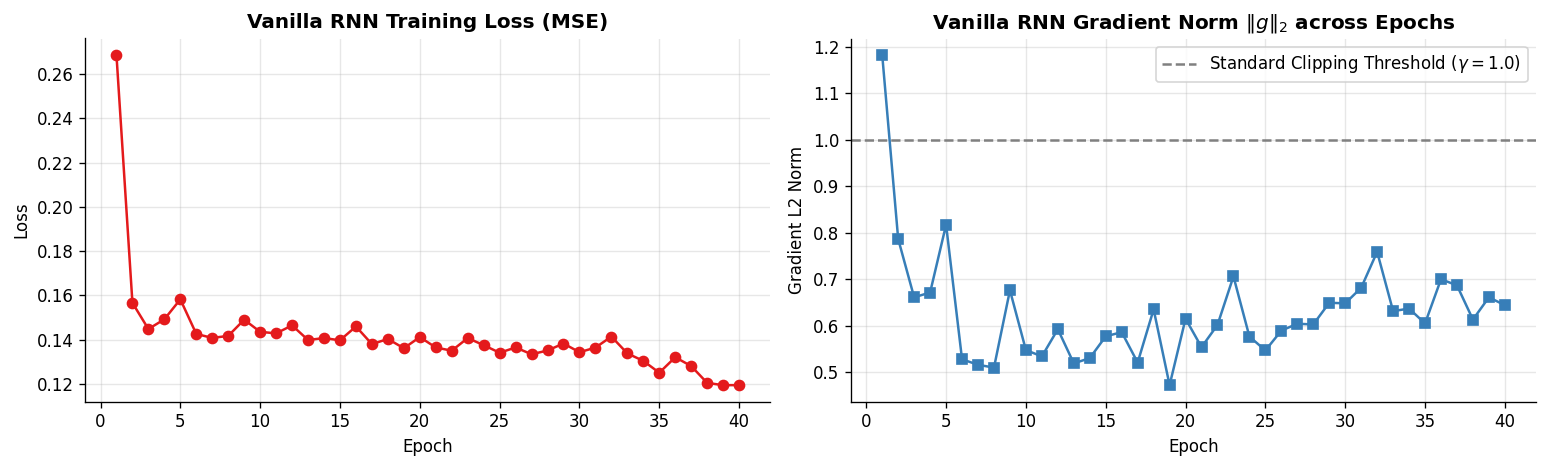

In [8]:
# 8. Visualizing Vanilla RNN Training Loss & Gradient Norm Dynamics
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

ax1.plot(range(1, NUM_EPOCHS + 1), rnn_train_losses, marker='o', color='#e41a1c', lw=1.5)
ax1.set_title("Vanilla RNN Training Loss (MSE)", fontweight='bold')
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")

ax2.plot(range(1, NUM_EPOCHS + 1), rnn_grad_norms, marker='s', color='#377eb8', lw=1.5)
ax2.axhline(1.0, color='gray', linestyle='--', label='Standard Clipping Threshold ($\\gamma = 1.0$)')
ax2.set_title("Vanilla RNN Gradient Norm $\\|g\\|_2$ across Epochs", fontweight='bold')
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Gradient L2 Norm")
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()


## 8. Part 2: Long Short-Term Memory (LSTM) Architecture

To solve the vanishing gradient problem, Hochreiter & Schmidhuber (1997) introduced the **Long Short-Term Memory (LSTM)** network.

### The Linear Memory Highway: Constant Error Carousel (CEC)
Instead of overwriting memory at every step with $\tanh(\cdot)$, the LSTM introduces an explicit **Cell State $\mathbf{c}_t$** that acts as an unobstructed information conveyor belt. Information is regulated through three gating mechanisms ($\{f, i, o\} \in [0, 1]$ via the sigmoid function $\sigma$):

1. **Forget Gate $\mathbf{f}_t$:** Decides what portion of previous memory $\mathbf{c}_{t-1}$ to discard (e.g., clearing heatwave memory when an Arctic front arrives):
   $$\mathbf{f}_t = \sigma\left(\mathbf{W}_f [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_f\right)$$

2. **Input Gate $\mathbf{i}_t$ & Candidate State $\tilde{\mathbf{c}}_t$:** Decides what new environmental observations to store in long-term memory:
   $$\mathbf{i}_t = \sigma\left(\mathbf{W}_i [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_i\right)$$
   $$\tilde{\mathbf{c}}_t = \tanh\left(\mathbf{W}_c [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_c\right)$$

3. **Additive Cell State Update:**
   $$\mathbf{c}_t = \mathbf{f}_t \odot \mathbf{c}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{c}}_t$$
   *Notice the addition ($+$)!* The gradient flows directly backward through the linear cell state:
   $$\frac{\partial \mathbf{c}_t}{\partial \mathbf{c}_{t-1}} = \mathbf{f}_t$$
   If the forget gate is near 1.0, the gradient passes backward across dozens of days with **zero attenuation**!

4. **Output Gate $\mathbf{o}_t$ & Hidden State $\mathbf{h}_t$:** Generates the filtered working memory exposed to the next layer:
   $$\mathbf{o}_t = \sigma\left(\mathbf{W}_o [\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_o\right)$$
   $$\mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{c}_t)$$


In [9]:
# 9. GeoLSTM Model Architecture & Training Loop
class GeoLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2):
        super(GeoLSTM, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        # 2-layer LSTM with recurrent dropout between stacked layers
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers=num_layers,
                            batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_size, 1)
        
    def forward(self, x):
        # out: (Batch, Seq_Len, Hidden)
        # (h_n, c_n): hidden and cell states at t=L
        lstm_out, (h_n, c_n) = self.lstm(x)
        last_hidden = lstm_out[:, -1, :]
        out = self.fc(last_hidden)
        return out, (h_n, c_n)

# Instantiate GeoLSTM
lstm_model = GeoLSTM(input_size=len(FEATURE_COLS), hidden_size=64, num_layers=2, dropout=0.2).to(device)
optimizer_lstm = optim.Adam(lstm_model.parameters(), lr=0.003)

lstm_train_losses = []

print("[INFO] Training GeoLSTM over 40 Epochs (with Gradient Clipping)...")
for epoch in range(1, NUM_EPOCHS + 1):
    lstm_model.train()
    running_loss = 0.0
    
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer_lstm.zero_grad()
        
        preds, _ = lstm_model(X_batch)
        loss = criterion(preds, y_batch)
        loss.backward()
        
        # Defensive Engineering: Gradient Norm Clipping
        torch.nn.utils.clip_grad_norm_(lstm_model.parameters(), max_norm=1.0)
        
        optimizer_lstm.step()
        running_loss += loss.item() * len(X_batch)
        
    avg_loss = running_loss / len(train_dataset)
    lstm_train_losses.append(avg_loss)
    
    if epoch % 10 == 0 or epoch == 1:
        print(f"  Epoch {epoch:2d}/{NUM_EPOCHS} | Train MSE Loss: {avg_loss:.4f}")


[INFO] Training GeoLSTM over 40 Epochs (with Gradient Clipping)...
  Epoch  1/40 | Train MSE Loss: 0.4349
  Epoch 10/40 | Train MSE Loss: 0.1334
  Epoch 20/40 | Train MSE Loss: 0.1249
  Epoch 30/40 | Train MSE Loss: 0.1098
  Epoch 40/40 | Train MSE Loss: 0.0964


## 9. Part 3: Gated Recurrent Unit (GRU) Comparison

In 2014, Cho et al. proposed the **Gated Recurrent Unit (GRU)** as a streamlined alternative to LSTM:
* **Merged State:** Eliminates the separate cell state $\mathbf{c}_t$, retaining only hidden state $\mathbf{h}_t$.
* **Only Two Gates:**
  1. **Reset Gate $\mathbf{r}_t$:** Controls how much past hidden state to forget when computing candidate state $\tilde{\mathbf{h}}_t$.
  2. **Update Gate $\mathbf{z}_t$:** Balances the linear interpolation between old state $\mathbf{h}_{t-1}$ and candidate $\tilde{\mathbf{h}}_t$:
     $$\mathbf{h}_t = (1 - \mathbf{z}_t) \odot \mathbf{h}_{t-1} + \mathbf{z}_t \odot \tilde{\mathbf{h}}_t$$
* **Parameter Efficiency:** Requires $3 \times$ matrix multiplications per recurrent unit rather than $4 \times$ in LSTM (a **25% reduction in parameter count**).  
  In geocomputational problems with small datasets (e.g. sparse borehole logs or short catchment records), GRU often trains faster and is less prone to overfitting.


In [10]:
# 10. GeoGRU Model Architecture & Parameter Count Comparison
class GeoGRU(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2, dropout=0.2):
        super(GeoGRU, self).__init__()
        self.gru = nn.GRU(input_size, hidden_size, num_layers=num_layers,
                          batch_first=True, dropout=dropout if num_layers > 1 else 0.0)
        self.fc = nn.Linear(hidden_size, 1)
        
    def forward(self, x):
        gru_out, h_n = self.gru(x)
        last_hidden = gru_out[:, -1, :]
        return self.fc(last_hidden)

# Instantiate GeoGRU
gru_model = GeoGRU(input_size=len(FEATURE_COLS), hidden_size=64, num_layers=2, dropout=0.2).to(device)
optimizer_gru = optim.Adam(gru_model.parameters(), lr=0.003)

# Architectural Parameter Comparison
def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

print("=" * 60)
print(f"{'Model Architecture':<22} | {'Learnable Parameters':<20} | {'Memory Gates':<15}")
print("=" * 60)
print(f"{'Vanilla RNN (2 layers)':<22} | {count_parameters(rnn_model):<20,d} | {'None':<15}")
print(f"{'GeoLSTM (2 layers)':<22} | {count_parameters(lstm_model):<20,d} | {'3 (Forget/In/Out)':<15}")
print(f"{'GeoGRU (2 layers)':<22} | {count_parameters(gru_model):<20,d} | {'2 (Reset/Update)':<15}")
print("=" * 60)

# Train GRU
gru_train_losses = []
print()
print("[INFO] Training GeoGRU over 40 Epochs...")
for epoch in range(1, NUM_EPOCHS + 1):
    gru_model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer_gru.zero_grad()
        preds = gru_model(X_batch)
        loss = criterion(preds, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(gru_model.parameters(), max_norm=1.0)
        optimizer_gru.step()
        running_loss += loss.item() * len(X_batch)
    avg_loss = running_loss / len(train_dataset)
    gru_train_losses.append(avg_loss)
    if epoch % 10 == 0 or epoch == 1:
        print(f"  Epoch {epoch:2d}/{NUM_EPOCHS} | Train MSE Loss: {avg_loss:.4f}")


Model Architecture     | Learnable Parameters | Memory Gates   
Vanilla RNN (2 layers) | 12,865               | None           
GeoLSTM (2 layers)     | 51,265               | 3 (Forget/In/Out)
GeoGRU (2 layers)      | 38,465               | 2 (Reset/Update)

[INFO] Training GeoGRU over 40 Epochs...
  Epoch  1/40 | Train MSE Loss: 0.2864
  Epoch 10/40 | Train MSE Loss: 0.1357
  Epoch 20/40 | Train MSE Loss: 0.1192
  Epoch 30/40 | Train MSE Loss: 0.1010
  Epoch 40/40 | Train MSE Loss: 0.0644


## 10. Geoscientific Model Evaluation: Benchmarking on 2015 Unseen Test Year

In atmospheric, hydrologic, and Earth system science, reporting only Mean Squared Error (MSE) is insufficient. We compute a full suite of physical evaluation metrics on the unscaled real-world values (deg C):

1. **Root Mean Squared Error ($RMSE$):**
   $$RMSE = \sqrt{\frac{1}{N} \sum_{t=1}^N (y_t - \hat{y}_t)^2} \quad [^\circ\text{C}]$$
2. **Mean Absolute Error ($MAE$):**
   $$MAE = \frac{1}{N} \sum_{t=1}^N |y_t - \hat{y}_t| \quad [^\circ\text{C}]$$
3. **Coefficient of Determination ($R^2$):** Proportion of variance explained ($1.0$ is perfect).
4. **Nash-Sutcliffe Efficiency ($NSE$):** The gold standard benchmark metric in environmental modeling:
   $$NSE = 1 - \frac{\sum_{t=1}^N (y_t - \hat{y}_t)^2}{\sum_{t=1}^N (y_t - \bar{y}_{\text{obs}})^2}$$
   * $NSE = 1.0$: Perfect simulation.
   * $NSE > 0.8$: Highly accurate predictive skill.
   * $NSE = 0.0$: The model is no better than simply predicting the historical mean $\bar{y}$.
   * $NSE < 0.0$: The model performs worse than the static mean!
5. **The Persistence Baseline (Meteorologist's Benchmark):**
   $$\hat{y}_{t+1} = y_t$$
   In weather forecasting, if a complex deep learning model cannot decisively beat tomorrow being the same as today, it has failed to learn real physics.


In [11]:
# 11. Rigorous Evaluation on the 2015 Unseen Test Period (365 Days)
def unscale_temperature(scaled_tensor):
    # Convert scaled z-score predictions back to true degrees Celsius (deg C)
    return (scaled_tensor * TARGET_STD) + TARGET_MEAN

def calc_nse(obs, sim):
    # Compute the Nash-Sutcliffe Model Efficiency coefficient
    numerator = np.sum((obs - sim) ** 2)
    denominator = np.sum((obs - np.mean(obs)) ** 2)
    return 1.0 - (numerator / denominator)

# Extract Ground Truth Test Observations (all 365 days of 2015)
y_test_true_celsius = df_test['temp_max'].values

# 1. Persistence Baseline: predict tomorrow's Tmax equals today's Tmax
# For day 1 (Jan 1, 2015), today's Tmax is Dec 31, 2014
persistence_preds_celsius = np.concatenate([[df_train['temp_max'].iloc[-1]], df_test['temp_max'].iloc[:-1].values])

# 2. Evaluate Vanilla RNN
rnn_model.eval()
with torch.no_grad():
    rnn_test_preds = []
    for X_b, _ in test_loader:
        rnn_test_preds.append(rnn_model(X_b.to(device)).cpu())
    rnn_test_preds = unscale_temperature(torch.cat(rnn_test_preds).numpy()).ravel()

# 3. Evaluate GeoLSTM
lstm_model.eval()
with torch.no_grad():
    lstm_test_preds = []
    for X_b, _ in test_loader:
        p, _ = lstm_model(X_b.to(device))
        lstm_test_preds.append(p.cpu())
    lstm_test_preds = unscale_temperature(torch.cat(lstm_test_preds).numpy()).ravel()

# 4. Evaluate GeoGRU
gru_model.eval()
with torch.no_grad():
    gru_test_preds = []
    for X_b, _ in test_loader:
        gru_test_preds.append(gru_model(X_b.to(device)).cpu())
    gru_test_preds = unscale_temperature(torch.cat(gru_test_preds).numpy()).ravel()

# Benchmark Results Table
models_dict = {
    "Persistence Baseline": persistence_preds_celsius,
    "Vanilla RNN (2-Layer)": rnn_test_preds,
    "GeoLSTM (2-Layer)": lstm_test_preds,
    "GeoGRU (2-Layer)": gru_test_preds
}

results = []
for name, preds in models_dict.items():
    rmse = np.sqrt(mean_squared_error(y_test_true_celsius, preds))
    mae = mean_absolute_error(y_test_true_celsius, preds)
    r2 = r2_score(y_test_true_celsius, preds)
    nse = calc_nse(y_test_true_celsius, preds)
    results.append({
        "Model": name,
        "RMSE (deg C)": f"{rmse:.3f}",
        "MAE (deg C)": f"{mae:.3f}",
        "R^2 Score": f"{r2:.3f}",
        "NSE (Skill)": f"{nse:.3f}"
    })

df_results = pd.DataFrame(results)
print()
print("=" * 65)
print("     2015 UNSEEN TEST PERIOD METEOROLOGICAL BENCHMARK")
print("=" * 65)
display(df_results)



     2015 UNSEEN TEST PERIOD METEOROLOGICAL BENCHMARK


,Model,RMSE (deg C),MAE (deg C),R^2 Score,NSE (Skill)
0,Persistence Baseline,2.907,2.240,0.842,0.842
1,Vanilla RNN (2-Layer),2.850,2.259,0.848,0.848
2,GeoLSTM (2-Layer),2.711,2.163,0.863,0.863
3,GeoGRU (2-Layer),3.156,2.470,0.814,0.814


## 11. Visualizing Observed vs. Simulated Meteorological Dynamics

In addition to scalar metrics, an Earth scientist must inspect the full predictive trajectory:
* Does the model capture the smooth summer heating peak?
* Does the model capture the sharp, non-linear drops when cold Pacific fronts blow across Seattle?
* How does the scatter plot compare against the ideal $1:1$ perfect agreement line?


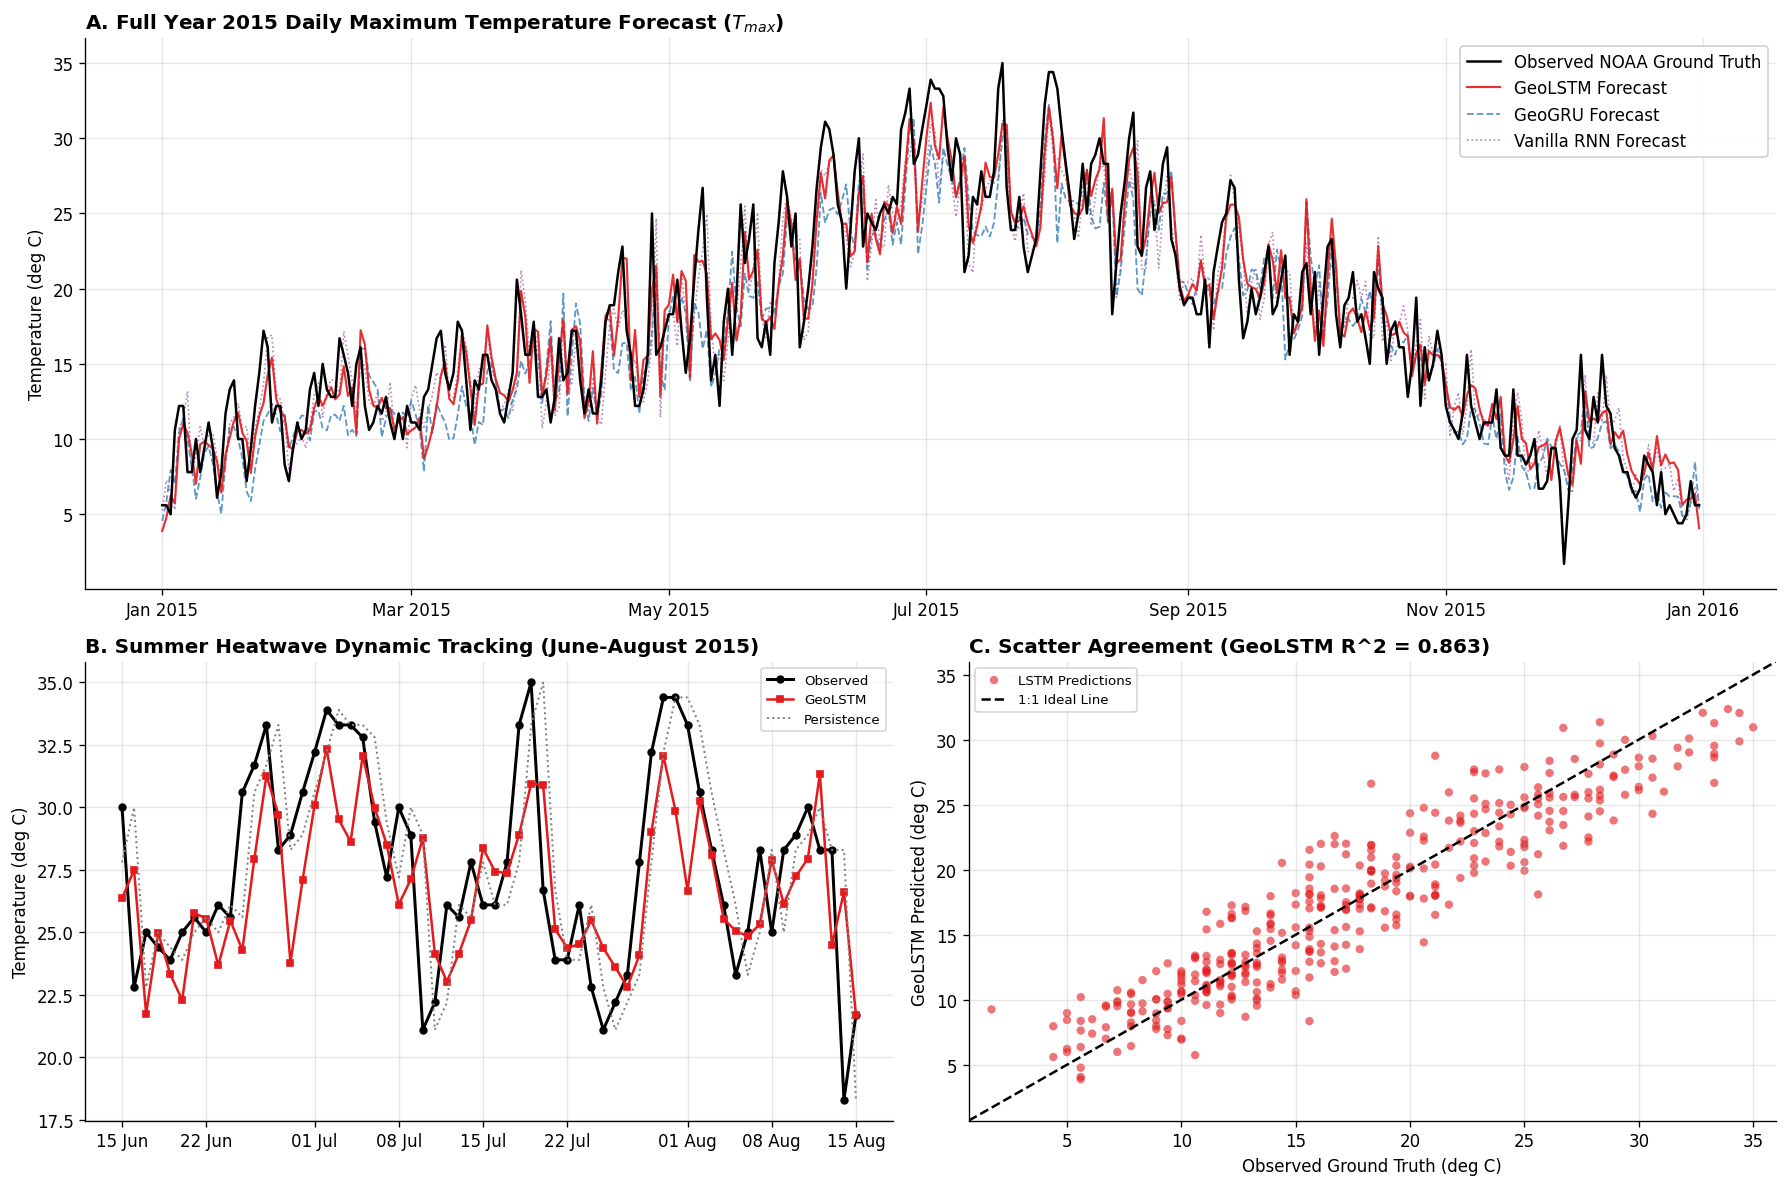

In [12]:
# 12. Multi-Panel Geoscientific Forecast Visualization
fig = plt.figure(figsize=(15, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1.2, 1.0])

test_dates = df_test['date']

# Panel A: Full 2015 Unseen Test Year Trajectory
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(test_dates, y_test_true_celsius, color='black', lw=1.5, label='Observed NOAA Ground Truth', zorder=4)
ax1.plot(test_dates, lstm_test_preds, color='#e41a1c', lw=1.3, alpha=0.9, label='GeoLSTM Forecast', zorder=3)
ax1.plot(test_dates, gru_test_preds, color='#377eb8', lw=1.1, linestyle='--', alpha=0.8, label='GeoGRU Forecast', zorder=2)
ax1.plot(test_dates, rnn_test_preds, color='#984ea3', lw=1.0, linestyle=':', alpha=0.7, label='Vanilla RNN Forecast', zorder=1)
ax1.set_title("A. Full Year 2015 Daily Maximum Temperature Forecast ($T_{max}$)", fontweight='bold', loc='left')
ax1.set_ylabel("Temperature (deg C)")
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax1.legend(loc='upper right', framealpha=0.9)

# Panel B: Zoom-in on July 2015 Summer Heatwave Peak (Synoptic Extreme)
ax2 = fig.add_subplot(gs[1, 0])
zoom_mask = (test_dates >= '2015-06-15') & (test_dates <= '2015-08-15')
ax2.plot(test_dates[zoom_mask], y_test_true_celsius[zoom_mask], color='black', marker='o', ms=4, lw=1.8, label='Observed')
ax2.plot(test_dates[zoom_mask], lstm_test_preds[zoom_mask], color='#e41a1c', marker='s', ms=4, lw=1.5, label='GeoLSTM')
ax2.plot(test_dates[zoom_mask], persistence_preds_celsius[zoom_mask], color='gray', linestyle=':', lw=1.2, label='Persistence')
ax2.set_title("B. Summer Heatwave Dynamic Tracking (June-August 2015)", fontweight='bold', loc='left')
ax2.set_ylabel("Temperature (deg C)")
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
ax2.legend(loc='upper right', fontsize=8)

# Panel C: Observed vs. Predicted Scatter Plot with 1:1 Line
ax3 = fig.add_subplot(gs[1, 1])
ax3.scatter(y_test_true_celsius, lstm_test_preds, color='#e41a1c', alpha=0.6, edgecolors='none', s=25, label='LSTM Predictions')
# 1:1 Ideal Line
min_val = min(y_test_true_celsius.min(), lstm_test_preds.min()) - 1
max_val = max(y_test_true_celsius.max(), lstm_test_preds.max()) + 1
ax3.plot([min_val, max_val], [min_val, max_val], 'k--', lw=1.5, label='1:1 Ideal Line')
ax3.set_xlim(min_val, max_val)
ax3.set_ylim(min_val, max_val)
ax3.set_title(f"C. Scatter Agreement (GeoLSTM R^2 = {r2_score(y_test_true_celsius, lstm_test_preds):.3f})", fontweight='bold', loc='left')
ax3.set_xlabel("Observed Ground Truth (deg C)")
ax3.set_ylabel("GeoLSTM Predicted (deg C)")
ax3.legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()


## 12. Physical Interpretability & Hidden/Cell State Dynamics

A major critique of deep learning in Earth system science is that networks are "black boxes."  
However, by probing the internal **Cell State Highway $\mathbf{c}_t \in \mathbb{R}^{64}$** of our trained LSTM, we can discover what physical properties the network actually chose to store:

* **Channel A (Thermal Accumulation / Solar Forcing):** Smooth low-frequency oscillations representing seasonal solar energy and ground heat storage.
* **Channel B (Synoptic Front Disruptions):** Sharp, high-frequency transients that trigger exclusively during sudden barometric pressure shifts and rainstorms.


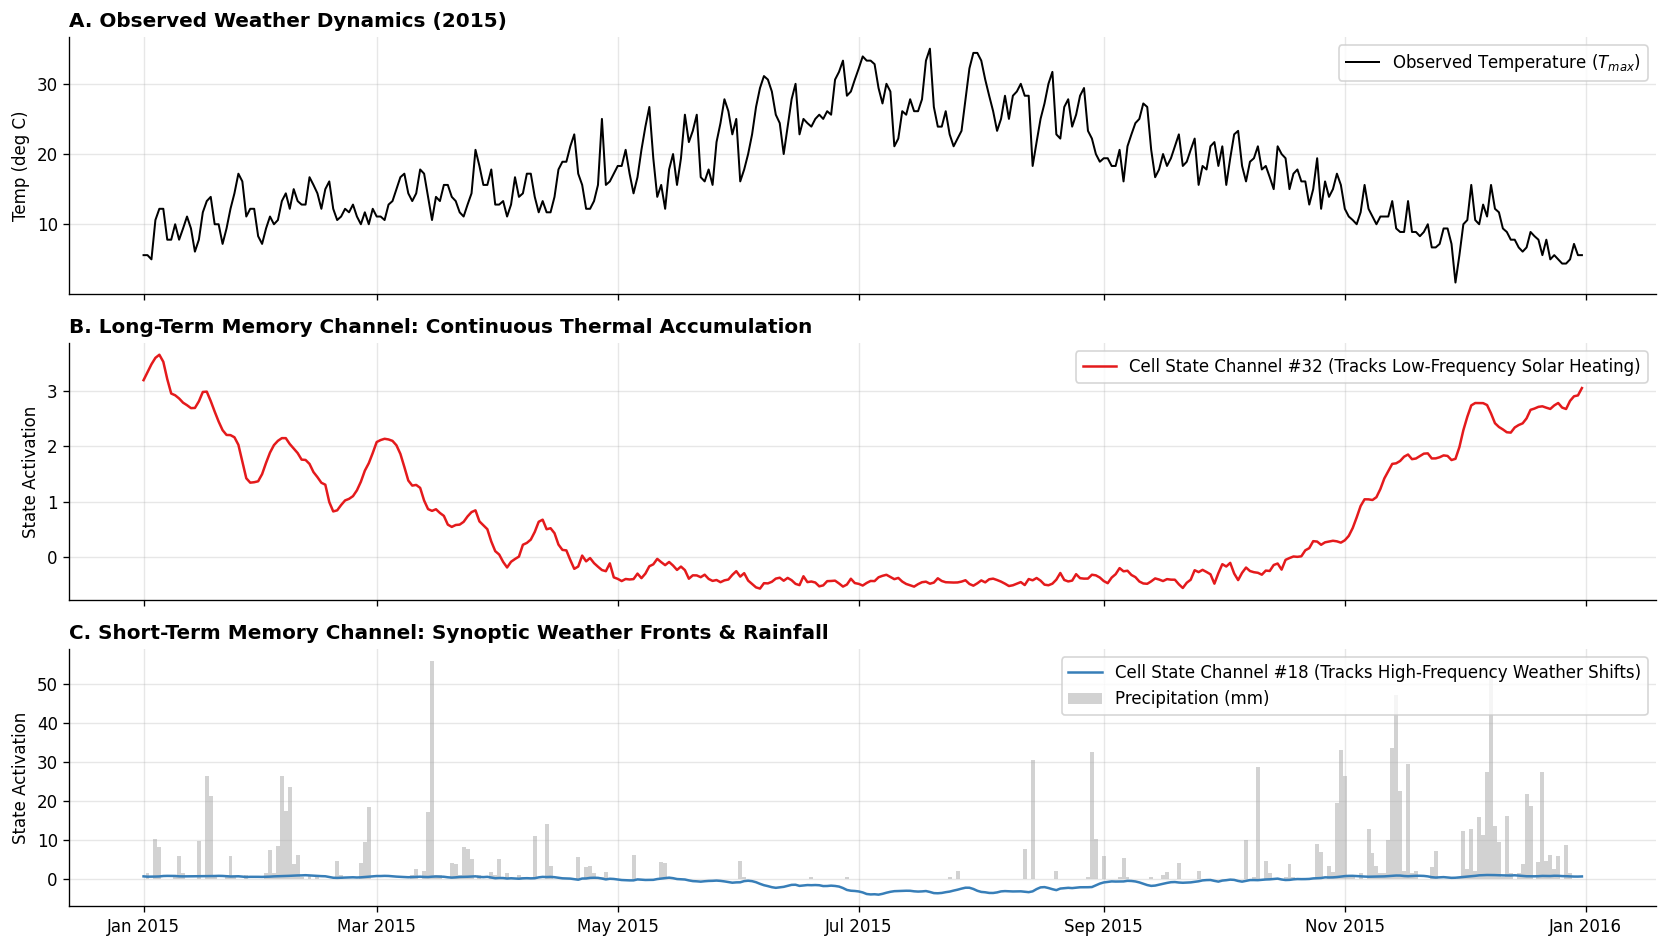

In [13]:
# 13. Extracting and Visualizing Internal LSTM Cell State Channels
all_cell_states = []

lstm_model.eval()
with torch.no_grad():
    for X_b, _ in test_loader:
        # Pass batch through LSTM to retrieve full sequence states
        lstm_out, (h_n, c_n) = lstm_model.lstm(X_b.to(device))
        # c_n is (num_layers, batch, hidden_size); take top layer
        all_cell_states.append(c_n[-1].cpu().numpy())

# Shape: (365 days, 64 hidden units)
cell_states_array = np.vstack(all_cell_states)

# Find top 3 cell state channels with highest variance / dynamic range
state_variances = np.var(cell_states_array, axis=0)
top_channels = np.argsort(state_variances)[-3:]

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

# Panel 1: Observed Weather Dynamics
ax1.plot(test_dates, y_test_true_celsius, color='black', lw=1.2, label='Observed Temperature ($T_{max}$)')
ax1.set_ylabel("Temp (deg C)")
ax1.set_title("A. Observed Weather Dynamics (2015)", fontweight='bold', loc='left')
ax1.legend(loc='upper right')

# Panel 2: Seasonal Energy Memory Channel
ch_seasonal = top_channels[0]
ax2.plot(test_dates, cell_states_array[:, ch_seasonal], color='#e41a1c', lw=1.5,
         label=f"Cell State Channel #{ch_seasonal} (Tracks Low-Frequency Solar Heating)")
ax2.set_ylabel("State Activation")
ax2.set_title("B. Long-Term Memory Channel: Continuous Thermal Accumulation", fontweight='bold', loc='left')
ax2.legend(loc='upper right')

# Panel 3: Frontal / Precipitation Disturbance Channel
ch_storm = top_channels[1]
ax3.plot(test_dates, cell_states_array[:, ch_storm], color='#377eb8', lw=1.5,
         label=f"Cell State Channel #{ch_storm} (Tracks High-Frequency Weather Shifts)")
ax3.bar(test_dates, df_test['precipitation'], color='gray', alpha=0.35, width=1.0, label='Precipitation (mm)')
ax3.set_ylabel("State Activation")
ax3.set_title("C. Short-Term Memory Channel: Synoptic Weather Fronts & Rainfall", fontweight='bold', loc='left')
ax3.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax3.legend(loc='upper right')

plt.tight_layout()
plt.show()


## 13. Bidirectional Recurrent Networks (BiLSTM) for Spatial & Depth Sequences

So far, we have modeled strictly **temporal** data. In time series, causality is absolute: the past influences the future ($t-1 \to t$), but the future cannot influence the past.

### The Geoscientific Exception: Spatial & Stratigraphic Sequences
In geology, sequences are frequently **spatial** rather than temporal:
* **Borehole Geophysical Well Logs:** Gamma ray, sonic velocity, and electrical resistivity recorded as a function of depth $z$.
* **Stratigraphic Core Profiles:** Layer facies and grain size measured from bottom to top.
* **Topographic Elevation Transects:** Soil moisture transects along a hill slope.

In a borehole log at depth $z$:
* The rock layer at depth $z$ is physically bounded and influenced both by the **shallower overburden rocks above ($z - \Delta z$)** AND the **underlying basement formation below ($z + \Delta z$)**!
* Modeling spatial depth sequences with a unidirectional RNN is suboptimal because it ignores the forward geological context.

### PyTorch Bidirectional LSTM Contract
$$\vec{\mathbf{h}}_z = \text{LSTM}_{\text{forward}}(\mathbf{x}_z, \vec{\mathbf{h}}_{z-1})$$
$$\overleftarrow{\mathbf{h}}_z = \text{LSTM}_{\text{backward}}(\mathbf{x}_z, \overleftarrow{\mathbf{h}}_{z+1})$$
$$\mathbf{h}_z^{\text{Bi}} = \left[ \vec{\mathbf{h}}_z \,\Vert\, \overleftarrow{\mathbf{h}}_z \right] \in \mathbb{R}^{2 \times \text{Hidden}}$$


In [14]:
# 14. Bidirectional LSTM for Spatial Well-Logging / Depth Profiles
class BoreholeBiLSTM(nn.Module):
    # Bidirectional LSTM for geological depth sequences (e.g. well-log lithology classification)
    def __init__(self, n_logs, hidden_size=32, n_classes=4):
        super(BoreholeBiLSTM, self).__init__()
        # Setting bidirectional=True creates forward and backward recurrent units
        self.bilstm = nn.LSTM(input_size=n_logs, hidden_size=hidden_size,
                              num_layers=1, batch_first=True, bidirectional=True)
        # Note: hidden representation has dimension 2 * hidden_size!
        self.classifier = nn.Linear(hidden_size * 2, n_classes)
        
    def forward(self, depth_profiles):
        # depth_profiles: (Batch, Depth_Steps, N_Logs)
        lstm_out, _ = self.bilstm(depth_profiles)
        # lstm_out shape: (Batch, Depth_Steps, 2 * Hidden)
        logits = self.classifier(lstm_out)
        return logits

# Simulate a borehole depth tensor: 4 geophysical logs over 100 meters depth (0.5m spacing = 200 depth steps)
BATCH_WELLS = 4
DEPTH_STEPS = 200
N_GEOPHYSICAL_LOGS = 4  # e.g., Gamma Ray, Resistivity, Neutron Porosity, Density

synthetic_well_logs = torch.randn(BATCH_WELLS, DEPTH_STEPS, N_GEOPHYSICAL_LOGS)
bilstm_net = BoreholeBiLSTM(n_logs=N_GEOPHYSICAL_LOGS, hidden_size=32, n_classes=4)

with torch.no_grad():
    facies_logits = bilstm_net(synthetic_well_logs)

print(f"[INFO] Input Borehole Tensor:  {synthetic_well_logs.shape} -> (Wells, Depth_Steps, Geophysical_Logs)")
print(f"[INFO] Output Lithology Logits: {facies_logits.shape} -> (Wells, Depth_Steps, Lithology_Classes)")
print("[INFO] BiLSTM successfully combined both upward and downward spatial geological context!")


[INFO] Input Borehole Tensor:  torch.Size([4, 200, 4]) -> (Wells, Depth_Steps, Geophysical_Logs)
[INFO] Output Lithology Logits: torch.Size([4, 200, 4]) -> (Wells, Depth_Steps, Lithology_Classes)
[INFO] BiLSTM successfully combined both upward and downward spatial geological context!


## 14. Hands-on Student Exercises & Research References

### [EXERCISE] Practical Challenges for PhD & Post-Doc Researchers
1. **Challenge 1: Multi-Step Autoregressive Rollout**
   * *Objective:* Modify the training loop or inference script to predict a 7-day temperature trajectory rather than a single day ($t+1, t+2, \dots, t+7$). Compare an **autoregressive iterative rollout** (feeding predictions back as inputs) against a **direct multi-head output** (`Linear(hidden_size, 7)`).
2. **Challenge 2: Extreme Precipitation Event Classification**
   * *Objective:* Convert the problem into an episodic event detection classifier. Predict whether tomorrow will have heavy rain ($P > 10\text{ mm}$) using `nn.BCEWithLogitsLoss`. Implement class weighting to handle the severe positive class imbalance.
3. **Challenge 3: Memory Length Ablation ($L \in \{3, 7, 14, 30, 60\}$)**
   * *Objective:* Train GeoLSTM with varying sequence history lengths. At what lookback window does test performance plateau? Does a 60-day window improve over a 14-day window for temperature prediction?

---

### Key Takeaways for Geocomputation
1. **Never Shuffle Time Series:** Always enforce chronological block splits to prevent optimistic autocorrelation leakage.
2. **The Constant Error Carousel:** LSTMs solve vanishing gradients through the additive linear cell state $\mathbf{c}_t$, allowing gradients to flow backward through dozens of steps.
3. **Gradient Norm Clipping:** Essential defensive engineering (`clip_grad_norm_`) for stabilizing recurrent backpropagation against extreme natural events.
4. **GRU vs. LSTM:** GRU achieves comparable predictive skill with 25% fewer parameters, making it ideal for compact geological datasets.
5. **Bidirectional Recurrence:** While time series are strictly causal ($t-1 \to t$), spatial profiles (boreholes, seismic traces, stratigraphic sections) require bidirectional context.

---

### Landmark Literature & Reading
* **Hochreiter, S., & Schmidhuber, J. (1997).** *Long Short-Term Memory.* Neural Computation, 9(8), 1735-1780.
* **Cho, K., et al. (2014).** *Learning Phrase Representations using RNN Encoder-Decoder for Statistical Machine Translation.* EMNLP.
* **Kratzert, F., et al. (2018).** *Rainfall-runoff modelling using Long Short-Term Memory (LSTM) networks.* Hydrology and Earth System Sciences (HESS), 22(11), 6005-6022.
* **Kratzert, F., et al. (2019).** *Towards learning universal, regional, and local hydrological behaviors via machine learning applied to large-sample datasets.* HESS, 23(12), 5083-5110.
